In [71]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [72]:
import sys
import os
sys.path.append(os.path.abspath('../src'))
import simpRepair
import simplification

In [73]:
import sys
import os
sys.path.append(os.path.abspath('../src'))
import matplotlib.pyplot as plt
import numpy as np

from torchvision.io import read_image
from pathlib import Path
import torchvision.transforms.functional as F

from torchvision.models.segmentation import fcn_resnet50

from torchvision.transforms.functional import convert_image_dtype
from torchvision.transforms.functional import crop
from torchvision.transforms.functional import resize

import torch
from torchvision.utils import draw_segmentation_masks

from torchvision.transforms import GaussianBlur
from torchvision.transforms.v2 import GaussianNoise
import numpy as np
import pywt
from skimage.measure import shannon_entropy, blur_effect
import cv2
import imagecodecs
import simplification
import visualization_utils

from data_utils import get_data_module
from model_builder import get_dynunet_module, get_swinunetr_module
from omegaconf import OmegaConf

In [74]:
name_dynunet_32 = "model-dynunet_2026-01-28-12-58"  # 32
name_swin = "model-swinunetr_2026-01-28-13-12"

In [264]:
swinunet_cfg = OmegaConf.load("../configs/monai_swinunetr.yaml")
dynunet_32_cfg = OmegaConf.load("../configs/monai_dynunet_32.yaml")


mnmDataModule = get_data_module(dataset='mnmv2',
                                data_dir='/mnt/extraStorage/MNM',
                                data_split="challenge_wo_GE",
                                batch_size=1,
                                binary_target=False,
                                non_empty_target=True,
                                normalize="instanceNormSlice")

mnmDataModule.setup(stage="test")

GE [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 70, 101, 102, 103, 104, 105, 106, 107, 108, 109, 141, 142, 145, 171, 176, 177, 186, 187, 191, 192, 196, 206, 207, 208, 209, 210, 256, 270, 289, 302, 303, 304, 317, 318, 319, 323, 324, 325, 326, 336]
before removal train 160
new len train set 134
before removal val 40
new len validation set 32
before removal test 160
new len test set 141
set up test data
load data
200
201
202
203
204
205
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
257
258
259
260
261
262
263
264
265
266
267
268
269
271
272
273
274
275
276
277
278
279
280
281
282
283
284
285
286
287
288
290
291
292
293
294
295
296
297
298
299
300
301
305
306
307
308
309
310
311
312
313
314
315
316
320
321
322
327
328
329
330
331
332
333
334
335
337
338
339
340
341
342
343
344
345
346
347
348
349
350
351
352
353
354
355
356
357
358
359
Normalized using instan

In [265]:
# swinunetr
checkpoint_path = f"../models/{name_swin}.ckpt"
swin = get_swinunetr_module(cfg=swinunet_cfg,
                            load_from_checkpoint=True,
                            checkpoint_path=checkpoint_path)
swin.eval()

# dynunet 32
checkpoint_path = f"../models/{name_dynunet_32}.ckpt"
unet32 = get_dynunet_module(cfg=dynunet_32_cfg,
                            load_from_checkpoint=True,
                            checkpoint_path=checkpoint_path)
unet32.eval()

/home/amikliss/miniforge3/envs/segStrategiesEnv/lib/python3.11/site-packages/lightning/fabric/utilities/cloud_io.py:73: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.


Using DiceCELoss
type strides <class 'omegaconf.listconfig.ListConfig'>
type kernel_size <class 'int'>
strides [1, 2, 2, 2]
../results/modelsMNM/model-dynunet_2025-06-12-16-48.ckpt
Using DiceCELoss


LightningSegmentationModel(
  (model): DynUNet(
    (input_block): UnetBasicBlock(
      (conv1): Convolution(
        (conv): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (adn): ADN(
          (D): Dropout(p=0.0, inplace=False)
        )
      )
      (conv2): Convolution(
        (conv): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (adn): ADN(
          (D): Dropout(p=0.0, inplace=False)
        )
      )
      (lrelu): LeakyReLU(negative_slope=0.01, inplace=True)
      (norm1): InstanceNorm2d(32, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
      (norm2): InstanceNorm2d(32, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    )
    (downsamples): ModuleList(
      (0): UnetBasicBlock(
        (conv1): Convolution(
          (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
          (adn): ADN(
            (D): Dropout(p=0.0, inpl

In [ ]:
sample = 20
# 4
# 355

In [ ]:
input = mnmDataModule.mnm_test[sample]["input"][0].clone()
input[:60, :800] = input.min()
# input[:500,:80] = input.min()
print(input.shape)
gt = mnmDataModule.mnm_test[sample]["target"][0]
out_swin = swin(input.to(swin.device).unsqueeze(0).unsqueeze(0))
out_swin_org = out_swin
out_swin = torch.argmax(out_swin, dim=1)

out_unet = unet32(input.to(unet32.device).unsqueeze(0).unsqueeze(0))
print(out_unet.unique().sort())
out_unet_org = out_unet
out_unet = torch.argmax(out_unet, dim=1)

torch.Size([256, 256])
torch.return_types.sort(
values=tensor([-10.9552, -10.6367, -10.6236,  ...,  13.2892,  13.4397,  13.5346],
       device='cuda:0', grad_fn=<SortBackward0>),
indices=tensor([     0,      1,      2,  ..., 240153, 240154, 240155], device='cuda:0'))


(np.float64(-0.5), np.float64(255.5), np.float64(255.5), np.float64(-0.5))

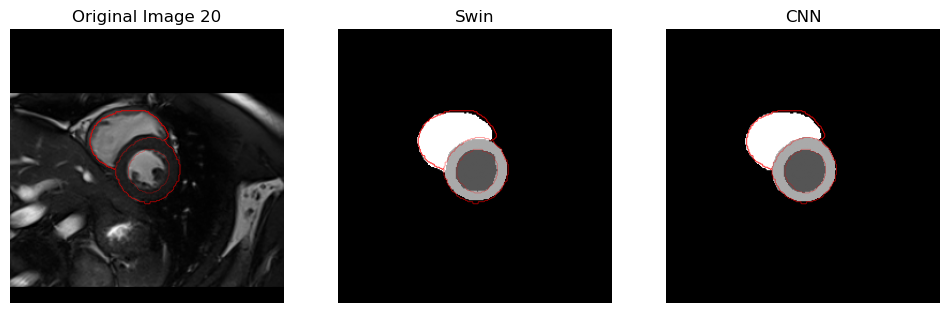

In [530]:
# Display results
plt.figure(figsize=(12, 6))
plt.subplot(1, 3, 1)
plt.imshow(input, cmap='gray')
plt.title(f'Original Image {sample}')
plt.contour(gt.cpu(), colors='red', linewidths=0.1)
plt.axis('off')

# Display results
plt.subplot(1, 3, 2)
plt.imshow(out_swin.cpu()[0], cmap='gray')
plt.contour(gt.cpu(), colors='red', linewidths=0.1)
plt.title('Swin')
plt.axis('off')


plt.subplot(1, 3, 3)
plt.imshow(out_unet.cpu()[0], cmap='gray')
plt.contour(gt.cpu(), colors='red', linewidths=0.1)
plt.title('CNN')
plt.axis('off')

In [507]:
print(len(input.shape))

2


simp torch.Size([1, 256, 256])


/tmp/ipykernel_398866/104305617.py:17: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  simp = torch.tensor(input.clone()).unsqueeze(0)


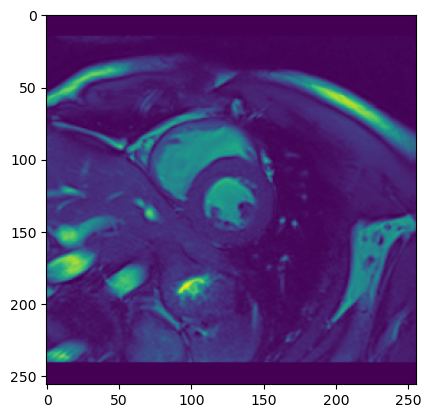

0
torch.Size([1, 256, 256])
value torch.Size([256, 256])
Soft thresholding with lambda=0.1. For new lambda reinitalize the WaveletSimplification class
value min -0.913517
value max 5.468953
min tensor(-0.9135)
max tensor(5.4690)


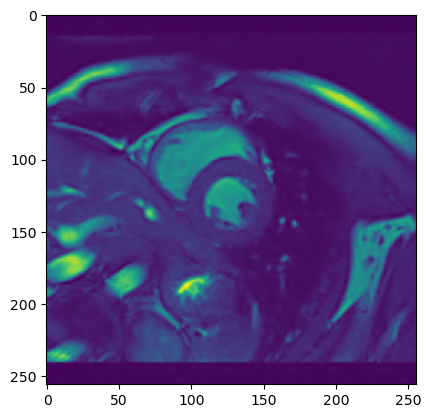

1
torch.Size([1, 256, 256])
value torch.Size([256, 256])
Soft thresholding with lambda=0.2. For new lambda reinitalize the WaveletSimplification class
value min -1.0449297
value max 5.3786817
min tensor(-1.0449)
max tensor(5.3787)


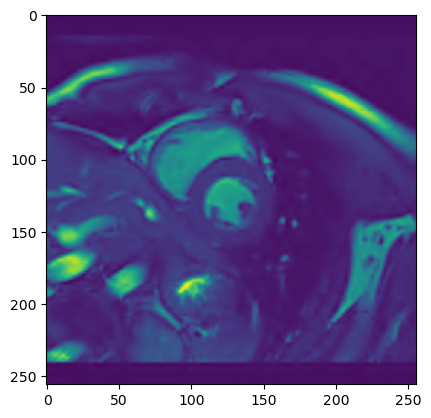

2
torch.Size([1, 256, 256])
value torch.Size([256, 256])
Soft thresholding with lambda=0.4. For new lambda reinitalize the WaveletSimplification class
value min -1.1220218
value max 5.186163
min tensor(-1.1220)
max tensor(5.1862)


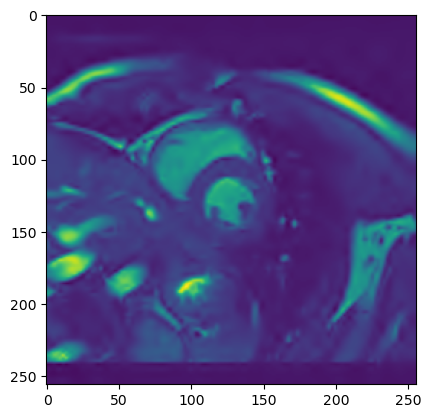

3
torch.Size([1, 256, 256])
value torch.Size([256, 256])
Soft thresholding with lambda=0.8. For new lambda reinitalize the WaveletSimplification class
value min -1.0838953
value max 5.015022
min tensor(-1.0839)
max tensor(5.0150)


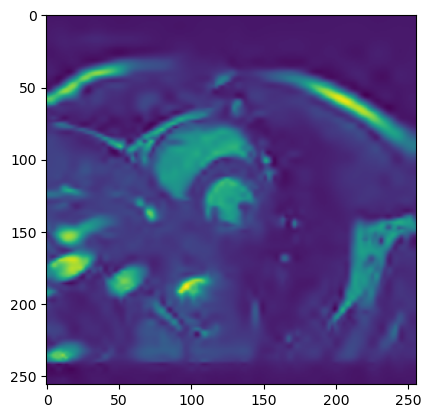

4
torch.Size([1, 256, 256])
value torch.Size([256, 256])
Soft thresholding with lambda=1.6. For new lambda reinitalize the WaveletSimplification class
value min -1.15116
value max 4.7535048
min tensor(-1.1512)
max tensor(4.7535)


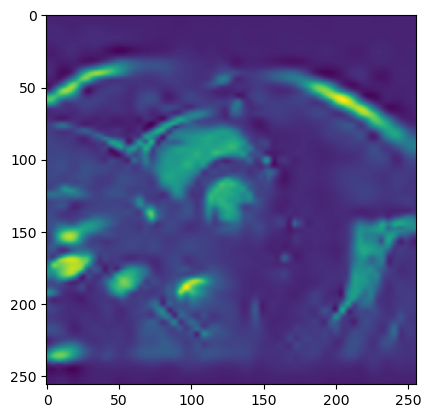

5
torch.Size([1, 256, 256])
value torch.Size([256, 256])
Soft thresholding with lambda=3.2. For new lambda reinitalize the WaveletSimplification class
value min -1.199379
value max 4.5575533
min tensor(-1.1994)
max tensor(4.5576)


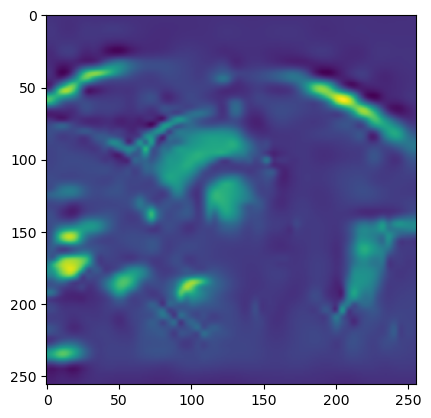

6
torch.Size([1, 256, 256])
value torch.Size([256, 256])
Soft thresholding with lambda=6.4. For new lambda reinitalize the WaveletSimplification class
value min -1.2836108
value max 4.1446004
min tensor(-1.2836)
max tensor(4.1446)


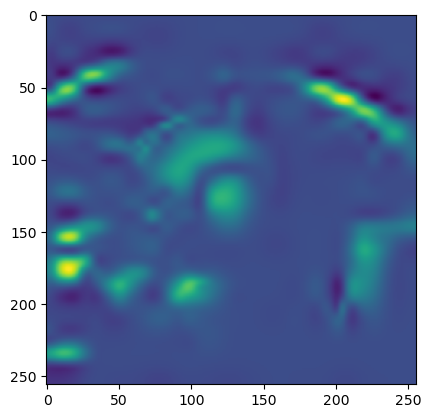

7
torch.Size([1, 256, 256])
value torch.Size([256, 256])
Soft thresholding with lambda=12.8. For new lambda reinitalize the WaveletSimplification class
value min -1.1335089
value max 3.5464957
min tensor(-1.1335)
max tensor(3.5465)


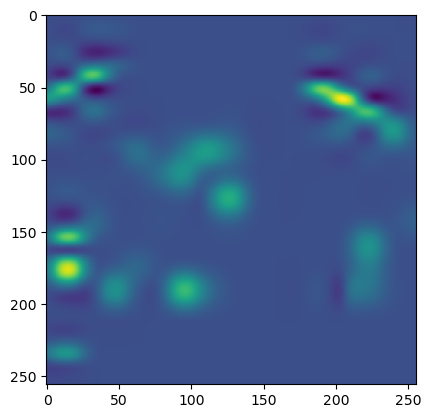

8
torch.Size([1, 256, 256])
value torch.Size([256, 256])
Soft thresholding with lambda=25.6. For new lambda reinitalize the WaveletSimplification class
value min -0.70138824
value max 1.9279902
min tensor(-0.7014)
max tensor(1.9280)


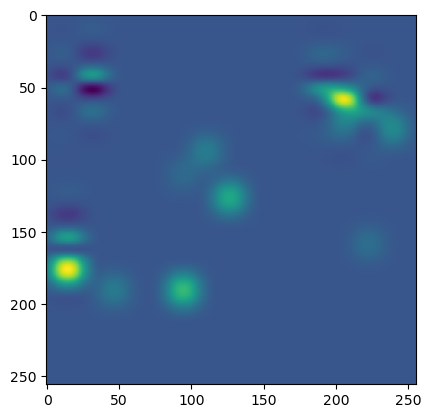

9
torch.Size([1, 256, 256])
value torch.Size([256, 256])
Soft thresholding with lambda=51.2. For new lambda reinitalize the WaveletSimplification class
value min 0.0
value max 0.0
min tensor(0.)
max tensor(0.)


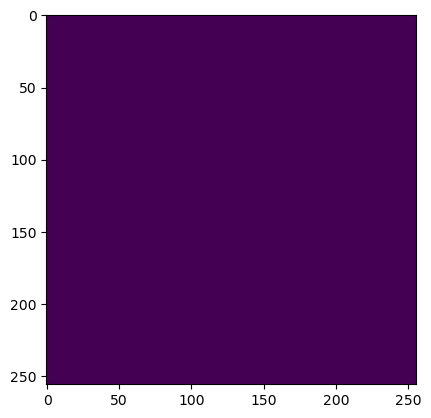

10
torch.Size([1, 256, 256])
value torch.Size([256, 256])
Soft thresholding with lambda=102.4. For new lambda reinitalize the WaveletSimplification class
value min 0.0
value max 0.0
min tensor(0.)
max tensor(0.)


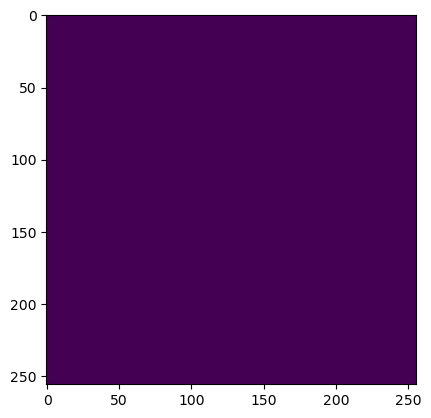

11
torch.Size([1, 256, 256])
value torch.Size([256, 256])
Soft thresholding with lambda=204.8. For new lambda reinitalize the WaveletSimplification class
value min 0.0
value max 0.0
min tensor(0.)
max tensor(0.)


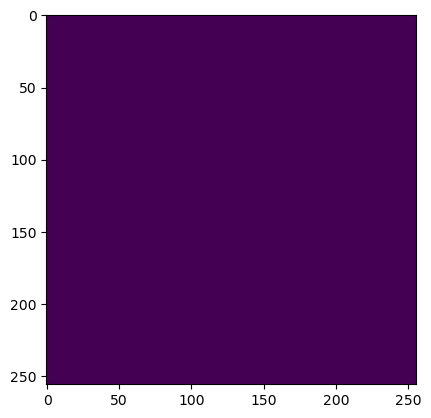

12
torch.Size([1, 256, 256])
value torch.Size([256, 256])
Soft thresholding with lambda=409.6. For new lambda reinitalize the WaveletSimplification class
value min 0.0
value max 0.0
min tensor(0.)
max tensor(0.)


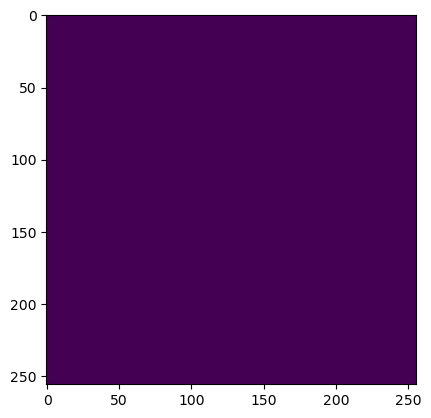

In [508]:
quantizer = simplification.ColorQuantizationSimplification(
    colors=80, lamb_mul=0.75)
# for i in range(20):
#     print(i)
#     simp = quantizer.simplify(img)
#     print(simp)
#     plt.imshow(torch.moveaxis(simp, 0, -1))
#     plt.show()

bilateral = simplification.Bilateral_Filter(
    sigma_color=0.01, inc_sigma_color=1.3, sigma_spatial=7)

blur = simplification.Gaussian_Blur(sigma=0.5, inc=1.5)

wavelet = simplification.WaveletSimplification(
    levels=4, lamb_soft_thresholding_compression=0.1, lamb_mul=2)
simp = torch.tensor(input.clone()).unsqueeze(0)
# simp = torch.stack([simp, simp, simp])
print("simp", simp.shape)
plt.imshow(simp[0])
plt.show()
for i in range(13):
    print(i)
    simp = wavelet.simplify(simp)
    print("min", simp.min())
    print("max", simp.max())
    plt.imshow(simp.cpu()[0])
    # plt.imshow(torch.moveaxis(simp.cpu(), 0, -1))
    plt.show()